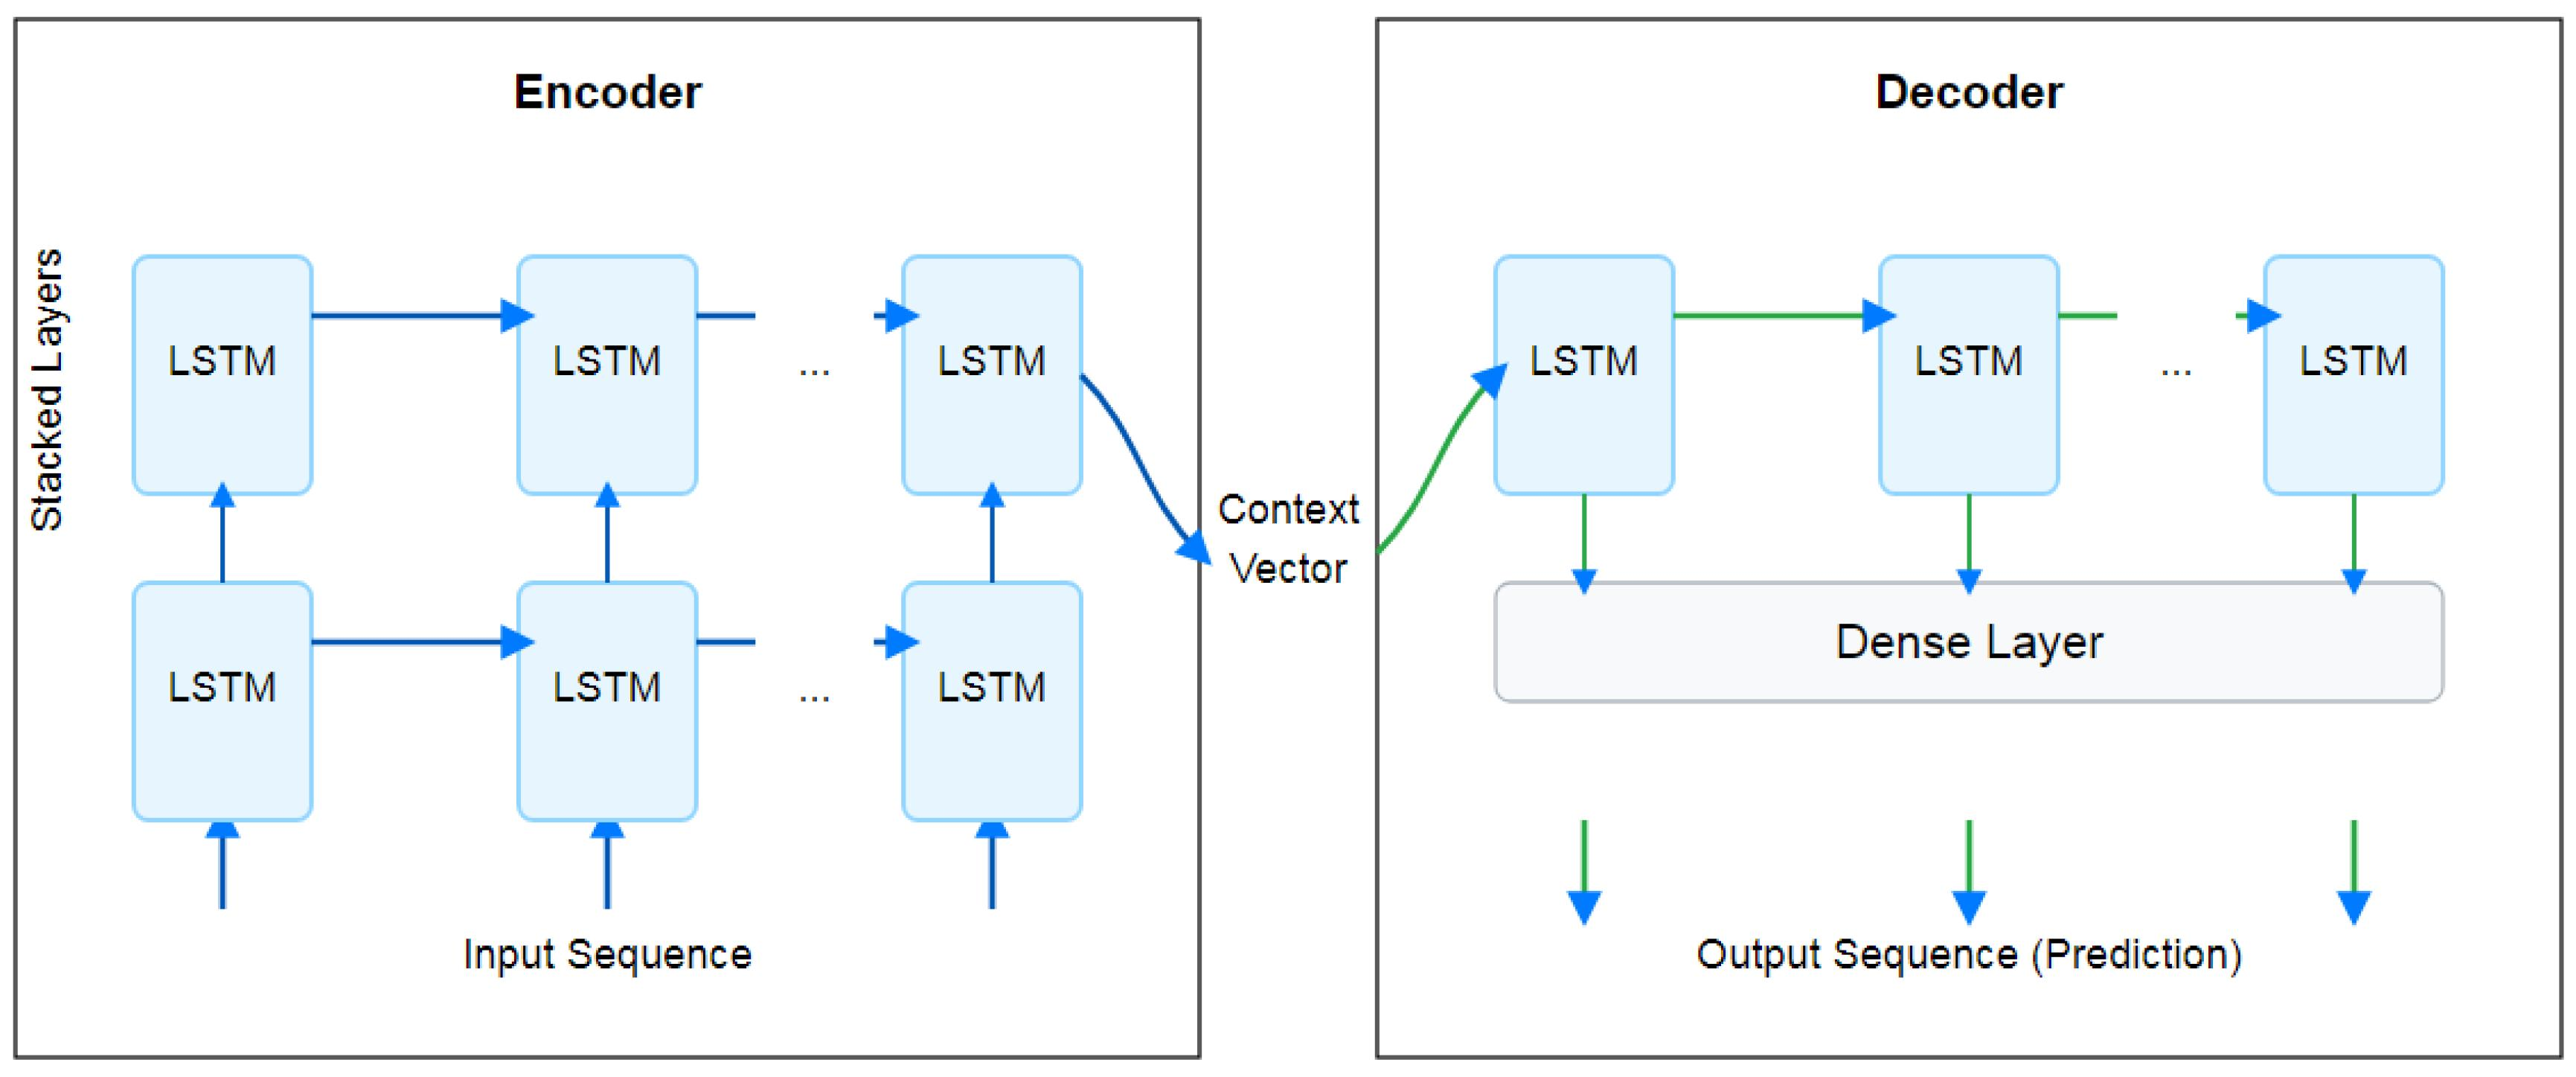

**Next word predication using SEQ2SEQ model tensorflow keras LSTM**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense
)

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

**dataset**

In [ ]:
text = """
I love machine learning
I love deep learning
I love artificial intelligence
Machine learning is very powerful
Deep learning uses neural networks
Artificial intelligence is changing the world
Python is a programming language
Python is used for machine learning
TensorFlow is a deep learning framework
LSTM is a recurrent neural network
RNN is used for sequential data
LSTM can remember long term dependencies
Neural networks learn from data
I am learning Python
I am learning deep learning
I am learning artificial intelligence
Machine learning is a part of artificial intelligence
Deep learning is a part of machine learning
"""

text = text.lower()

print(text)


i love machine learning
i love deep learning
i love artificial intelligence
machine learning is very powerful
deep learning uses neural networks
artificial intelligence is changing the world
python is a programming language
python is used for machine learning
tensorflow is a deep learning framework
lstm is a recurrent neural network
rnn is used for sequential data
lstm can remember long term dependencies
neural networks learn from data
i am learning python
i am learning deep learning
i am learning artificial intelligence
machine learning is a part of artificial intelligence
deep learning is a part of machine learning



**tokenization**

In [ ]:
tokenizer = Tokenizer(oov_token="<OOV>")

tokenizer.fit_on_texts(
    ["startseq endseq " + text]
)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)
print(tokenizer.word_index)

Vocabulary size: 44
{'<OOV>': 1, 'learning': 2, 'is': 3, 'i': 4, 'machine': 5, 'deep': 6, 'a': 7, 'artificial': 8, 'intelligence': 9, 'love': 10, 'neural': 11, 'python': 12, 'am': 13, 'networks': 14, 'used': 15, 'for': 16, 'lstm': 17, 'data': 18, 'part': 19, 'of': 20, 'startseq': 21, 'endseq': 22, 'very': 23, 'powerful': 24, 'uses': 25, 'changing': 26, 'the': 27, 'world': 28, 'programming': 29, 'language': 30, 'tensorflow': 31, 'framework': 32, 'recurrent': 33, 'network': 34, 'rnn': 35, 'sequential': 36, 'can': 37, 'remember': 38, 'long': 39, 'term': 40, 'dependencies': 41, 'learn': 42, 'from': 43}


**Create Seq2Seq training data**

In [ ]:
encoder_sequences = []
decoder_input_sequences = []
decoder_target_sequences = []

sentences = [
    line.strip()
    for line in text.split("\n")
    if line.strip()
]

for sentence in sentences:

    words = sentence.split()

    for i in range(1, len(words)):

        source = words[:i]

        target = words[i:] + ["endseq"]

        encoder_seq = tokenizer.texts_to_sequences(
            [" ".join(source)]
        )[0]

        target_seq = tokenizer.texts_to_sequences(
            [" ".join(target)]
        )[0]

        decoder_input = [
            tokenizer.word_index["startseq"]
        ] + target_seq[:-1]

        encoder_sequences.append(encoder_seq)
        decoder_input_sequences.append(decoder_input)
        decoder_target_sequences.append(target_seq)

print("Total training samples:", len(encoder_sequences))

Total training samples: 80


**padding**

In [ ]:
max_encoder_len = max(
    len(seq) for seq in encoder_sequences
)

max_decoder_len = max(
    len(seq) for seq in decoder_target_sequences
)

encoder_input = pad_sequences(
    encoder_sequences,
    maxlen=max_encoder_len,
    padding="post"
)

decoder_input = pad_sequences(
    decoder_input_sequences,
    maxlen=max_decoder_len,
    padding="post"
)

decoder_target = pad_sequences(
    decoder_target_sequences,
    maxlen=max_decoder_len,
    padding="post"
)

print("Encoder:", encoder_input.shape)
print("Decoder input:", decoder_input.shape)
print("Decoder target:", decoder_target.shape)

Encoder: (80, 7)
Decoder input: (80, 8)
Decoder target: (80, 8)


In [ ]:
embedding_dim = 128
latent_dim = 256

encoder_inputs = Input(
    shape=(max_encoder_len,),
    name="encoder_input"
)

encoder_embedding = Embedding(
    vocab_size,
    embedding_dim,
    mask_zero=True
)(encoder_inputs)

encoder_lstm = LSTM(
    latent_dim,
    return_state=True
)

_, state_h, state_c = encoder_lstm(
    encoder_embedding
)

encoder_states = [state_h, state_c]

**build decoder lstm**

In [ ]:
decoder_inputs = Input(
    shape=(max_decoder_len,),
    name="decoder_input"
)

decoder_embedding_layer = Embedding(
    vocab_size,
    embedding_dim,
    mask_zero=True
)

decoder_embedding = decoder_embedding_layer(
    decoder_inputs
)

decoder_lstm = LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=encoder_states
)

decoder_dense = Dense(
    vocab_size,
    activation="softmax"
)

decoder_outputs = decoder_dense(
    decoder_outputs
)

In [ ]:
model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 7, 128)    │      5,632 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 7)         │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 8, 128)    │      5,632 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 256),     │    394,240 │ embedding[0][0],  │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 8, 256),  │    394,240 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ lstm[0][1],       │
│                     │ (None, 256)]      │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8, 44)     │     11,308 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 811,052 (3.09 MB)

 Trainable params: 811,052 (3.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def masked_loss(y_true, y_pred):

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred
    )

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        loss.dtype
    )

    loss = loss * mask

    return tf.reduce_sum(loss) / (
        tf.reduce_sum(mask) + 1e-8
    )


model.compile(
    optimizer="adam",
    loss=masked_loss,
    metrics=["sparse_categorical_accuracy"]
)

In [ ]:
early_stop = EarlyStopping(
    monitor="loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    [encoder_input, decoder_input],
    decoder_target,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 3.7609 - sparse_categorical_accuracy: 0.2323
Epoch 2/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 3.6463 - sparse_categorical_accuracy: 0.2581
Epoch 3/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 3.2113 - sparse_categorical_accuracy: 0.2581
Epoch 4/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 3.0568 - sparse_categorical_accuracy: 0.2581
Epoch 5/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 2.7938 - sparse_categorical_accuracy: 0.2839
Epoch 6/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 2.7625 - sparse_categorical_accuracy: 0.3097
Epoch 7/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.6420 - sparse_categorical_accuracy: 0.2935
Epoch 8/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.5980 - sparse_categorical_accuracy: 0.2806
Epoch 9/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 2.5368 - sparse_categorical_accuracy: 0.3129
Epoch 10/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.4569 - spars